In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from helpers import *
import os
import pandas as pd

In [3]:
data_path = "data/dataset"
x_train, x_test, y_train, train_ids, test_ids = load_csv_data(data_path)

In [4]:
x_train_path = os.path.join(data_path, 'x_train.csv')
df_x_train = pd.read_csv(x_train_path)
y_train_path = os.path.join(data_path, 'y_train.csv')
df_y_train = pd.read_csv(y_train_path)
x_test_path = os.path.join(data_path, 'x_test.csv')
df_x_test = pd.read_csv(x_test_path)

In [5]:
df_x_train.head()

,Id,_STATE,FMONTH,IDATE,IMONTH,IDAY,IYEAR,DISPCODE,SEQNO,_PSU,...,_PAREC1,_PASTAE1,_LMTACT1,_LMTWRK1,_LMTSCL1,_RFSEAT2,_RFSEAT3,_FLSHOT6,_PNEUMO2,_AIDTST3
0,0,53,11,11162015,11,16,2015,1100,2015015629,2015015629,...,1,1,3.0,3.0,4.0,1,1,NaN,NaN,2.0
1,1,33,12,12152015,12,15,2015,1200,2015004387,2015004387,...,9,9,3.0,3.0,4.0,9,9,NaN,NaN,NaN
2,2,20,10,10202015,10,20,2015,1100,2015005638,2015005638,...,4,2,2.0,2.0,3.0,1,1,1.0,2.0,2.0
3,3,42,6,6182015,6,18,2015,1100,2015004694,2015004694,...,2,2,2.0,2.0,3.0,1,1,2.0,2.0,2.0
4,4,24,11,11062015,11,6,2015,1100,2015004673,2015004673,...,9,9,3.0,3.0,4.0,1,1,9.0,9.0,2.0


In [6]:
df_y_train.head()

,Id,_MICHD
0,0,-1
1,1,-1
2,2,-1
3,3,-1
4,4,-1


In [7]:
x_train.shape

(328135, 321)

# Clean Up Data

In [8]:
from helpers import *
from Code.costs import *
from Code.implementations import *

In [9]:
print("x_train shape:", x_train.shape)
print("NaN values:", np.isnan(x_train).sum())
print("Rows containing NaN:", np.isnan(x_train).any(axis=1).sum())
print("Rows without NaN:", (~np.isnan(x_train).any(axis=1)).sum())

x_train shape: (328135, 321)
NaN values: 47175779
Rows containing NaN: 328135
Rows without NaN: 0


In [10]:
## nouveau

nan_ratio = np.isnan(x_train).mean(axis=0)
mask = nan_ratio < 0.8
x_tr = x_train[:, mask]
x_te = x_test[:, mask]   

med = np.nanmedian(x_tr, axis=0)
x_tr = np.where(np.isnan(x_tr), med, x_tr)
x_te = np.where(np.isnan(x_te), med, x_te)

mean = x_tr.mean(axis=0)
std = x_tr.std(axis=0)
std[std == 0] = 1.0
x_tr = (x_tr - mean) / std
x_te = (x_te - mean) / std

## ancien

mask = ~np.isnan(x_train).any(axis=0) # selecting only features with no NaN => very dumb

x_train_clean = x_train[:,mask]
x_test_clean = x_test[:,mask]
y_train_clean = y_train

print('Remaining samples:', x_train_clean.shape)

Remaining samples: (328135, 82)


In [11]:
def normalize_data(x):
    return (x-np.mean(x, 0))/np.std(x,0)

x_train_clean = normalize_data(x_train_clean)
x_test_clean = normalize_data(x_test_clean)

# SGD Easy mode

In [12]:
num_samples = x_train_clean.shape[0]
tx_train = np.c_[np.ones(num_samples), x_train_clean]
tx_test = np.c_[np.ones(x_test_clean.shape[0]), x_test_clean]
x_tr =  np.c_[np.ones(num_samples), x_tr]

print("x_tr shape :", x_tr.shape)
num_samples, num_features = tx_train.shape
w_initial = np.zeros(num_features)

w_zero = np.zeros(x_tr.shape[1])


print(num_samples,num_features)
print(y_train_clean.shape)

x_tr shape : (328135, 206)
328135 83
(328135,)


In [34]:
w, loss = stochastic_gradient_descent(y_train_clean, tx_train, w_initial,batch_size=20, max_iters=100, gamma=0.01 )

SGD iter. 0/99: loss=0.4950204885594001, norm_w =0.024089420531792218
SGD iter. 1/99: loss=0.4870051149433224, norm_w =0.03970333560004622
SGD iter. 2/99: loss=0.4775716902242268, norm_w =0.04102932107375131
SGD iter. 3/99: loss=0.47257745895155084, norm_w =0.04954909835251931
SGD iter. 4/99: loss=0.46842393169630053, norm_w =0.0614981864088221
SGD iter. 5/99: loss=0.4571897742756532, norm_w =0.06932619167422861
SGD iter. 6/99: loss=0.45097398973269015, norm_w =0.07827500742314354
SGD iter. 7/99: loss=0.447114527895026, norm_w =0.08955160388078535
SGD iter. 8/99: loss=0.4422637498359258, norm_w =0.0957634076903704
SGD iter. 9/99: loss=0.42915851347018874, norm_w =0.09803002627703666
SGD iter. 10/99: loss=0.42451373891544986, norm_w =0.10466996041987615
SGD iter. 11/99: loss=0.42085580941181894, norm_w =0.11098221808777849
SGD iter. 12/99: loss=0.4165479547220836, norm_w =0.11715384167068703
SGD iter. 13/99: loss=0.41323250875016193, norm_w =0.1249268963275568
SGD iter. 14/99: loss=0.40

In [ ]:
## PRED + SUBMISSION FILE
pred = (tx_test @ w >= 0).astype(int)
pred[pred == 0] = -1
create_csv_submission(df_x_test["Id"], pred, "submission.csv")


(109379, 83)
(83,)


,Prediction
0,-1
1,-1
2,-1
3,-1
4,-1
...,...
109374,-1
109375,-1
109376,-1
109377,-1


In [13]:
w, loss = stochastic_gradient_descent(y_train, x_tr, w_zero, batch_size=20, max_iters=100, gamma=0.01 )

SGD iter. 0/99: loss=0.48926418993820053, norm_w =0.030239982157992448
SGD iter. 1/99: loss=0.48166003301627536, norm_w =0.04890905147010849
SGD iter. 2/99: loss=0.4744429410559935, norm_w =0.05684377344367475
SGD iter. 3/99: loss=0.46704248225837036, norm_w =0.06467412373376459
SGD iter. 4/99: loss=0.4568459927484894, norm_w =0.07151280422360456
SGD iter. 5/99: loss=0.4588831339674109, norm_w =0.08207278474827645
SGD iter. 6/99: loss=0.4485033463330757, norm_w =0.09435641181924029
SGD iter. 7/99: loss=0.44963553329957895, norm_w =0.10284440259142301
SGD iter. 8/99: loss=0.4392401162438892, norm_w =0.11275801572082704
SGD iter. 9/99: loss=0.44767304802310176, norm_w =0.1281009708051381
SGD iter. 10/99: loss=0.43811644271796446, norm_w =0.1337155737225858
SGD iter. 11/99: loss=0.4250736031699074, norm_w =0.13979910741488175
SGD iter. 12/99: loss=0.4159061675152593, norm_w =0.14122343799638604
SGD iter. 13/99: loss=0.41281750029764747, norm_w =0.14767012369924398
SGD iter. 14/99: loss=0.

# Cross Validation
### Cross Validation (k-fold) for **gamma** (learning rate)

In [14]:
def build_k_indices(y, k_fold, seed):
    """build k indices for k-fold.

    Args:
        y:      shape=(N,)
        k_fold: K in K-fold, i.e. the fold num
        seed:   the random seed

    Returns:
        A 2D array of shape=(k_fold, N/k_fold) that indicates the data indices for each fold

    >>> build_k_indices(np.array([1., 2., 3., 4.]), 2, 1)
    array([[3, 2],
           [0, 1]])
    """
    num_row = y.shape[0]
    interval = int(num_row / k_fold)
    np.random.seed(seed)
    indices = np.random.permutation(num_row)
    k_indices = [indices[k * interval : (k + 1) * interval] for k in range(k_fold)]
    return np.array(k_indices)

In [15]:
def cross_validation(y, x, k_indices, k, gamma, max_iters, batch_size):
    """return the loss of ridge regression for a fold corresponding to k_indices

    Args:
        y:          shape=(N,)
        x:          shape=(N,)
        k_indices:  2D array returned by build_k_indices()
        k:          scalar, the k-th fold (N.B.: not to confused with k_fold which is the fold nums)
        lambda_:    scalar, cf. ridge_regression()
        degree:     scalar, cf. build_poly()

    Returns:
        train and test root mean square errors rmse = sqrt(2 mse)

    >>> cross_validation(np.array([1.,2.,3.,4.]), np.array([6.,7.,8.,9.]), np.array([[3,2], [0,1]]), 1, 2, 3)
    (0.019866645527596753, 0.33555914361295197)
    """

    ### SOLUTION
    # get k'th subgroup in test, others in train
    te_indice = k_indices[k]
    tr_indice = k_indices[~(np.arange(k_indices.shape[0]) == k)]
    tr_indice = tr_indice.reshape(-1)
    y_te = y[te_indice]
    y_tr = y[tr_indice]
    x_te = x[te_indice]
    x_tr = x[tr_indice]
    # form data with constant
    tx_tr = np.c_[np.ones(x_tr.shape[0]), x_tr]
    tx_te = np.c_[np.ones(x_te.shape[0]), x_te]
    # SGD
    w_initial = np.zeros(tx_tr.shape[1])

    w, loss_tr = stochastic_gradient_descent(y_tr, tx_tr, w_initial, batch_size, max_iters, gamma)
    # calculate the loss for train and test data
    loss_te = compute_loss(y_te, tx_te, w)
    return float(loss_tr), float(loss_te)

In [16]:
from plots import cross_validation_visualization


def cross_validation_demo(y, x, k_fold, gammas, max_iters, batch_size):
    """cross validation over regularisation parameter lambda.

    Args:
        degree: integer, degree of the polynomial expansion
        k_fold: integer, the number of folds
        lambdas: shape = (p, ) where p is the number of values of lambda to test
    Returns:
        best_lambda : scalar, value of the best lambda
        best_rmse : scalar, the associated root mean squared error for the best lambda
    """

    seed = 12
    k_fold = k_fold
    # split data in k fold
    k_indices = build_k_indices(y, k_fold, seed)
    # define lists to store the loss of training data and test data
    rmse_tr = []
    rmse_te = []
    ### SOLUTION
    # cross validation
    for gamma in gammas:
        print("Computing gamma=", gamma, "----------------------------")
        rmse_tr_tmp = []
        rmse_te_tmp = []
        for k in range(k_fold):
            loss_tr, loss_te = cross_validation(y, x, k_indices, k, gamma, max_iters, batch_size)
            rmse_tr_tmp.append(loss_tr)
            rmse_te_tmp.append(loss_te)
        rmse_tr.append(np.mean(rmse_tr_tmp))
        rmse_te.append(np.mean(rmse_te_tmp))
    best_gamma, best_rmse = gammas[np.argmin(rmse_te)], np.min(rmse_te)
 

    cross_validation_visualization(gammas, rmse_tr, rmse_te)
    print(
        "For SGD, the choice of gamma which leads to the best test mse is %.5f with a test mse of %.3f"
        % (best_gamma, best_rmse)
    )
    return best_gamma, best_rmse

In [14]:
k_fold = 10
gammas = [0.001, 0.005 ,0.01, 0.05,0.1] #np.logspace(-4, 0, 30)
max_iters = 50
batch_size = 250

best_gamma, best_mse = cross_validation_demo(y_train_clean, x_train_clean, k_fold, gammas, max_iters, batch_size)

NameError: name 'cross_validation_demo' is not defined

Computing gamma= 0.001 ----------------------------
SGD iter. 0/49: loss=0.49848627910557747, norm_w =0.0015756881255656282
SGD iter. 1/49: loss=0.4969034375234563, norm_w =0.002756217196789917
SGD iter. 2/49: loss=0.49525748560907357, norm_w =0.004001237493188643
SGD iter. 3/49: loss=0.4934980748815917, norm_w =0.005366065646079965
SGD iter. 4/49: loss=0.4918410555506741, norm_w =0.006743108688758357
SGD iter. 5/49: loss=0.4902292510869085, norm_w =0.007989612003570979
SGD iter. 6/49: loss=0.48860904844902475, norm_w =0.009293750165320377
SGD iter. 7/49: loss=0.48724841205352853, norm_w =0.010361411237373991
SGD iter. 8/49: loss=0.4856313195353476, norm_w =0.011700805529828108
SGD iter. 9/49: loss=0.48413124255806234, norm_w =0.012888083074547639
SGD iter. 10/49: loss=0.482567375997646, norm_w =0.014158825184871665
SGD iter. 11/49: loss=0.48098482998076264, norm_w =0.015406654127453987
SGD iter. 12/49: loss=0.4794475074225246, norm_w =0.016673001452415348
SGD iter. 13/49: loss=0.47789

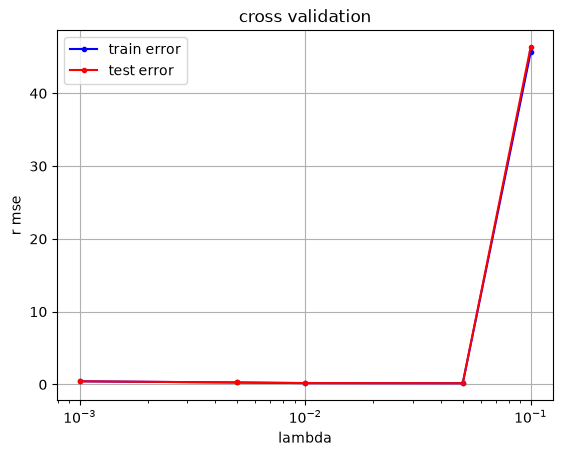

In [18]:
best_gamma, best_mse = cross_validation_demo(y_train, x_tr, k_fold, gammas, max_iters, batch_size)

### SGD with **L2 regularization** & Cross Validation on gammas

In [ ]:
def compute_gradient_reg(y, tx, w, lambda_):
    """Computes the gradient at w.

    Args:
        y: shape=(N, )
        tx: shape=(N,2)
        w: shape=(2, ). The vector of model parameters.

    Returns:
        An array of shape (2, ) (same shape as w), containing the gradient of the loss at w.
    """
    e = y - tx @ w

    reg = lambda_ * w.copy() # oui
    reg[0] = 0  # excluding intercept

    grad = -(tx.T @ e) / len(e) + reg
    return grad

In [87]:
def stochastic_gradient_descent_with_reg(y, tx, initial_w, batch_size, max_iters, gamma, lambda_):
    """The Stochastic Gradient Descent algorithm (SGD).

    Args:
        y: shape=(N, )
        tx: shape=(N,2)
        initial_w: shape=(2, ). The initial guess (or the initialization) for the model parameters
        batch_size: a scalar denoting the number of data points in a mini-batch used for computing the stochastic gradient
        max_iters: a scalar denoting the total number of iterations of SGD
        gamma: a scalar denoting the stepsize

    Returns:
        losses: a list of length max_iters containing the loss value (scalar) for each iteration of SGD
        ws: a list of length max_iters containing the model parameters as numpy arrays of shape (2, ), for each iteration of SGD
    """

    # Define parameters to store w and loss
    ws = [initial_w]
    losses = []
    w = initial_w

    for n_iter in range(max_iters):
        for y_batch, tx_batch in batch_iter(
            y, tx, batch_size=batch_size, num_batches=1
        ):
            # compute a stochastic gradient and loss
            grad = compute_gradient_reg(y_batch, tx_batch, w, lambda_)
            w = w - gamma * grad

            loss = compute_loss(y, tx, w, "mse")
            # store w and loss
            ws.append(w)
            losses.append(loss)

        print(
            "SGD iter. {bi}/{ti}: loss={l}, norm_w ={norm_w}".format(
                bi=n_iter, ti=max_iters - 1, l=loss, norm_w = np.linalg.norm(w)
            )
        )
    return w, loss

In [88]:
def cross_validation_with_reg(y, x, k_indices, k, gamma, max_iters, batch_size, lambda_):
    """return the loss of ridge regression for a fold corresponding to k_indices

    Args:
        y:          shape=(N,)
        x:          shape=(N,)
        k_indices:  2D array returned by build_k_indices()
        k:          scalar, the k-th fold (N.B.: not to confused with k_fold which is the fold nums)
        lambda_:    scalar, cf. ridge_regression()
        degree:     scalar, cf. build_poly()

    Returns:
        train and test root mean square errors rmse = sqrt(2 mse)

    >>> cross_validation(np.array([1.,2.,3.,4.]), np.array([6.,7.,8.,9.]), np.array([[3,2], [0,1]]), 1, 2, 3)
    (0.019866645527596753, 0.33555914361295197)
    """

    ### SOLUTION
    # get k'th subgroup in test, others in train
    te_indice = k_indices[k]
    tr_indice = k_indices[~(np.arange(k_indices.shape[0]) == k)]
    tr_indice = tr_indice.reshape(-1)
    y_te = y[te_indice]
    y_tr = y[tr_indice]
    x_te = x[te_indice]
    x_tr = x[tr_indice]
    # form data with constant
    tx_tr = np.c_[np.ones(x_tr.shape[0]), x_tr]
    tx_te = np.c_[np.ones(x_te.shape[0]), x_te]
    # SGD
    w_initial = np.zeros(tx_tr.shape[1])

    w, loss_tr = stochastic_gradient_descent_with_reg(y_tr, tx_tr, w_initial, batch_size, max_iters, gamma ,lambda_)
    # calculate the loss for train and test data
    loss_te = compute_loss(y_te, tx_te, w)
    return float(loss_tr), float(loss_te)

In [94]:
from plots import cross_validation_visualization


def cross_validation_demo_with_reg(y, x, k_fold, gammas, max_iters, batch_size, lambda_):
    """cross validation over regularisation parameter lambda.

    Args:
        degree: integer, degree of the polynomial expansion
        k_fold: integer, the number of folds
        lambdas: shape = (p, ) where p is the number of values of lambda to test
    Returns:
        best_lambda : scalar, value of the best lambda
        best_rmse : scalar, the associated root mean squared error for the best lambda
    """

    seed = 12
    k_fold = k_fold
    # split data in k fold
    k_indices = build_k_indices(y, k_fold, seed)
    # define lists to store the loss of training data and test data
    rmse_tr = []
    rmse_te = []
    ### SOLUTION
    # cross validation
    for gamma in gammas:
        print("Computing gamma=", gamma, "----------------------------")
        rmse_tr_tmp = []
        rmse_te_tmp = []
        for k in range(k_fold):
            loss_tr, loss_te = cross_validation_with_reg(y, x, k_indices, k, gamma, max_iters, batch_size, lambda_)
            rmse_tr_tmp.append(loss_tr)
            rmse_te_tmp.append(loss_te)
        rmse_tr.append(np.mean(rmse_tr_tmp))
        rmse_te.append(np.mean(rmse_te_tmp))
    best_gamma, best_rmse = gammas[np.argmin(rmse_te)], np.min(rmse_te)
 

    cross_validation_visualization(gammas, rmse_tr, rmse_te)
    print(
        "For SGD, the choice of gamma which leads to the best test mse is %.5f with a test mse of %.3f"
        % (best_gamma, best_rmse)
    )
    return best_gamma, best_rmse

Computing gamma= 0.001 ----------------------------
SGD iter. 0/49: loss=0.4992214182081199, norm_w =0.0010553771111940294
SGD iter. 1/49: loss=0.4984378328284988, norm_w =0.0018880727139907758
SGD iter. 2/49: loss=0.497638813516475, norm_w =0.0027422261043086225
SGD iter. 3/49: loss=0.4967616933715328, norm_w =0.003723591795420465
SGD iter. 4/49: loss=0.4959426409793371, norm_w =0.004732579554955893
SGD iter. 5/49: loss=0.4951363429303268, norm_w =0.005599243220435661
SGD iter. 6/49: loss=0.49428681526492735, norm_w =0.006556690417866018
SGD iter. 7/49: loss=0.4935814840765189, norm_w =0.007321949051222728
SGD iter. 8/49: loss=0.4927612699324192, norm_w =0.008287804717406746
SGD iter. 9/49: loss=0.4919929836087223, norm_w =0.009133578325214324
SGD iter. 10/49: loss=0.4912025560460918, norm_w =0.010022698960608189
SGD iter. 11/49: loss=0.49037793203804214, norm_w =0.010918001189369796
SGD iter. 12/49: loss=0.48960685675074184, norm_w =0.0118204914361095
SGD iter. 13/49: loss=0.48880022

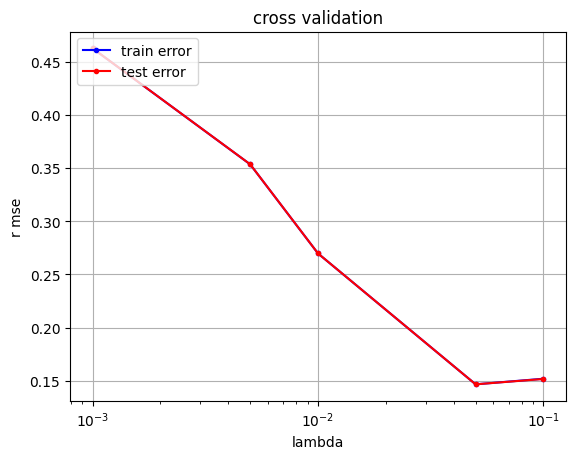

In [96]:
k_fold = 10
gammas = [0.001, 0.005 ,0.01, 0.05,0.1] #np.logspace(-4, 0, 30)
max_iters = 50
batch_size = 250
lambda_ = 0.05

best_gamma, best_mse = cross_validation_demo_with_reg(y_train_clean, x_train_clean, k_fold, gammas, max_iters, batch_size,lambda_)

### L2 Reg-SGD with Cross Validation over **gamma** & **lambda_**

In [ ]:
def best_gamma_lambda_selection(y,x, k_fold, gammas, max_iters, batch_size, lambdas, seed=1):
    """cross validation over regularisation parameter lambda and degree.

    Args:
        degrees: shape = (d,), where d is the number of degrees to test
        k_fold: integer, the number of folds
        lambdas: shape = (p, ) where p is the number of values of lambda to test
    Returns:
        best_degree : integer, value of the best degree
        best_lambda : scalar, value of the best lambda
        best_rmse : value of the rmse for the couple (best_degree, best_lambda)

    >>> best_degree_selection(np.arange(2,11), 4, np.logspace(-4, 0, 30))
    (7, 0.004520353656360241, 0.2895728056656946)
    """

    # split data in k fold
    k_indices = build_k_indices(y, k_fold, seed)

    # for each degree, we compute the best lambdas and the associated rmse
    best_lambdas = []
    best_rmses = []

    # vary degree
    for gamma in gammas:
        print('Computing gamma: ', gamma, '###################')
        # cross validation
        rmse_te = []
        for lambda_ in lambdas:
            print(f'Computing gamma: {gamma} & lambda: {lambda_}-------------')
            rmse_te_tmp = []
            for k in range(k_fold):
                _, loss_te = cross_validation_with_reg(y, x, k_indices, k, gamma, max_iters, batch_size, lambda_)
                rmse_te_tmp.append(loss_te)
            rmse_te.append(np.mean(rmse_te_tmp))

        ind_lambda_opt = np.argmin(rmse_te)
        best_lambdas.append(lambdas[ind_lambda_opt])
        best_rmses.append(rmse_te[ind_lambda_opt])

    ind_best_gamma = np.argmin(best_rmses)
    best_gamma = gammas[ind_best_gamma]
    best_lambda = best_lambdas[ind_best_gamma]
    best_rmse = best_rmses[ind_best_gamma]

    return int(best_gamma), float(best_lambda), float(best_rmse)

In [ ]:
k_fold = 10
gammas = [0.001, 0.005 ,0.01, 0.05,0.1] #np.logspace(-4, 0, 30)
max_iters = 50
batch_size = 250
lambdas = [0.001, 0.01, 0.1,1]

best_gamma, best_lambda, best_mse = best_gamma_lambda_selection(y_train_clean, x_train_clean, k_fold, gammas, max_iters, batch_size, lambdas)

Computing gamma:  0.001 ###################
Computing gamma: 0.001 & lambda: 0.001-------------
SGD iter. 0/49: loss=0.49926007549185625, norm_w =0.0010606900075002521
SGD iter. 1/49: loss=0.49849429399725737, norm_w =0.002002026452616374
SGD iter. 2/49: loss=0.49767284528142114, norm_w =0.0028980752887904637
SGD iter. 3/49: loss=0.4969632884835326, norm_w =0.00363765805845729
SGD iter. 4/49: loss=0.496074186160925, norm_w =0.004571503436357021
SGD iter. 5/49: loss=0.4952248129063369, norm_w =0.005598345806690887
SGD iter. 6/49: loss=0.49440072297441023, norm_w =0.006590639794318482
SGD iter. 7/49: loss=0.49365336538777754, norm_w =0.00742868167327697
SGD iter. 8/49: loss=0.4928455713180127, norm_w =0.008354262760865606
SGD iter. 9/49: loss=0.49211677952648003, norm_w =0.009111982494421062
SGD iter. 10/49: loss=0.49136643775162203, norm_w =0.009907696920313737
SGD iter. 11/49: loss=0.4905689385300913, norm_w =0.010775909841607104
SGD iter. 12/49: loss=0.4897811468383965, norm_w =0.0116

In [100]:
print(best_gamma, best_lambda, best_mse)

0 0.001 0.14655232071525978


## Logistic Reg

In [ ]:
max_iters = 1000
w, loss = logistic_regression(y_train, tx_train, w_initial, max_iters, gamma = 0.5)
print(loss) ## la loss est negative donc vraiment pas 
 

In [14]:
## PRED + SUBMISSION FILE
pred = (sigmoid(tx_test @ w) >= 0.5).astype(int)
pred[pred == 0] = -1
create_csv_submission(df_x_test["Id"], pred, "submission_log_reg.csv")